# 02 · Run Multi-Objective Evolutionary Search

Interactive notebook that launches the NSGA-II style search,
tracks hyper-volume, and visualises the resulting Pareto front.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path('..').resolve()))

import json
import numpy as np
import matplotlib.pyplot as plt

from nas.search_space import SearchSpace, Architecture
from nas.evolutionary import MultiObjectiveEvolutionarySearch

In [2]:
def proxy_evaluate(arch: Architecture):
    base = 70.0
    depth_score = min(arch.depth / 12.0, 1.0) * 10
    dim_score = min(arch.dim / 512.0, 1.0) * 8
    attn_bonus = {'softmax': 0.0, 'linear': 2.5, 'sparse-local': 1.5}.get(arch.attn_type, 0.0)
    overfit_pen = 4.0 if (arch.dim >= 768 and arch.depth >= 10) else 0.0
    acc = base + depth_score + dim_score + attn_bonus - overfit_pen
    acc = max(50.0, min(95.0, acc + (hash(str(arch)) % 100) / 50.0))
    space = SearchSpace()
    params = space.estimate_params(arch) / 1e6
    flops = space.estimate_flops(arch) / 1e9
    lat = 2.0 + params * 0.8 + (5.0 if arch.attn_type == 'softmax' else 1.5)
    return acc, params, flops, lat

In [3]:
space = SearchSpace()
searcher = MultiObjectiveEvolutionarySearch(
    search_space=space,
    evaluate_fn=proxy_evaluate,
    population_size=20,
    n_generations=10,
    seed=42,
)
front = searcher.run()
print(f'Pareto front size: {len(front)}')

[Gen 000] HV=89059999514.6423  best_acc=89.060  mean_acc=83.410  front=11
[Gen 001] HV=89059999516.0727  best_acc=89.060  mean_acc=83.010  front=21
[Gen 002] HV=89239999517.3693  best_acc=89.240  mean_acc=82.965  front=24
[Gen 003] HV=89239999519.6037  best_acc=89.240  mean_acc=83.957  front=29
[Gen 004] HV=92219999422.2766  best_acc=92.220  mean_acc=85.154  front=24
[Gen 005] HV=92219999444.6291  best_acc=92.220  mean_acc=85.284  front=22
[Gen 006] HV=92239999448.2583  best_acc=92.240  mean_acc=85.682  front=30
[Gen 007] HV=92239999448.5641  best_acc=92.240  mean_acc=86.814  front=31
[Gen 008] HV=92239999452.1092  best_acc=92.240  mean_acc=87.446  front=21
[Gen 009] HV=92239999452.1092  best_acc=92.240  mean_acc=88.229  front=35
Early stopping at generation 9
Pareto front size: 20


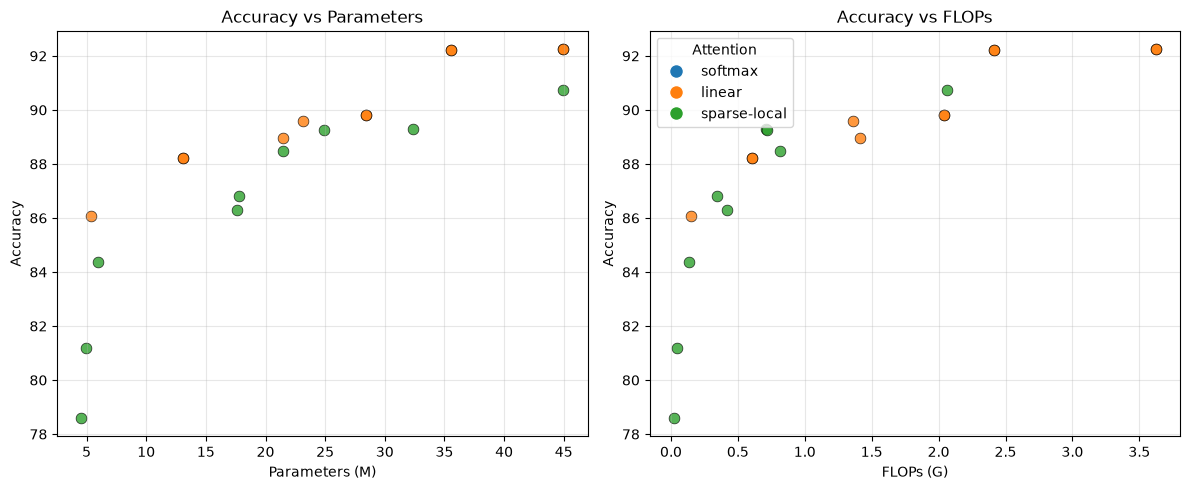

In [4]:
# Extract data for plotting
accs = [ind.fitness[0] for ind in front]
params = [-ind.fitness[1] for ind in front]
flops = [-ind.fitness[2] for ind in front]
lats = [-ind.fitness[3] for ind in front]
attns = [ind.arch.attn_type for ind in front]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

colors = {'softmax': 'C0', 'linear': 'C1', 'sparse-local': 'C2'}
for a, p, at in zip(accs, params, attns):
    axes[0].scatter(p, a, c=colors.get(at, 'gray'), s=60, alpha=0.8, edgecolors='k', linewidths=0.5)
axes[0].set_xlabel('Parameters (M)')
axes[0].set_ylabel('Accuracy')
axes[0].set_title('Accuracy vs Parameters')
axes[0].grid(True, alpha=0.3)

for a, f, at in zip(accs, flops, attns):
    axes[1].scatter(f, a, c=colors.get(at, 'gray'), s=60, alpha=0.8, edgecolors='k', linewidths=0.5)
axes[1].set_xlabel('FLOPs (G)')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Accuracy vs FLOPs')
axes[1].grid(True, alpha=0.3)

# legend
from matplotlib.lines import Line2D
handles = [Line2D([0],[0], marker='o', color='w', markerfacecolor=c, markersize=10, label=k)
           for k, c in colors.items()]
axes[1].legend(handles=handles, title='Attention')

plt.tight_layout()
plt.show()

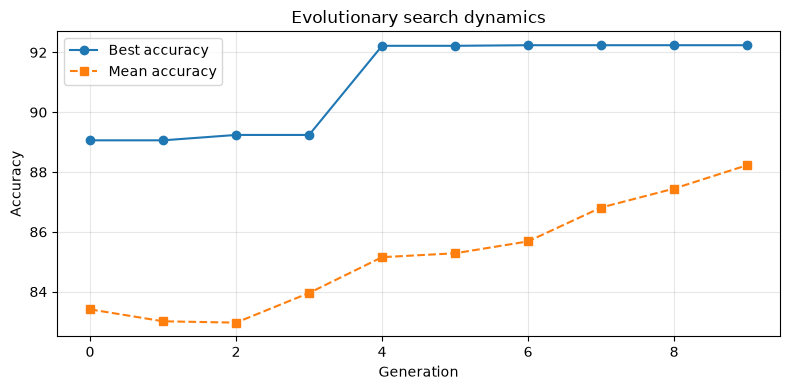

In [5]:
# Search dynamics
gens = [h['generation'] for h in searcher.history]
best = [h['best_acc'] for h in searcher.history]
mean = [h['mean_acc'] for h in searcher.history]
hv   = [h['hypervolume'] for h in searcher.history]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(gens, best, 'o-', label='Best accuracy')
ax.plot(gens, mean, 's--', label='Mean accuracy')
ax.set_xlabel('Generation')
ax.set_ylabel('Accuracy')
ax.legend()
ax.set_title('Evolutionary search dynamics')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
# Print top-5 architectures
print(f"{'Rank':<6}{'Depth':<7}{'Dim':<6}{'Heads':<7}{'Ratio':<7}{'Attn':<14}{'Acc':<8}{'Params':<10}{'Lat'}")
print('-'*70)
for i, ind in enumerate(sorted(front, key=lambda x: -x.fitness[0])[:5]):
    a = ind.arch
    print(f"{i:<6}{a.depth:<7}{a.dim:<6}{a.heads:<7}{a.ratio:<7.1f}{a.attn_type:<14}"
          f"{ind.fitness[0]:<8.1f}{-ind.fitness[1]:<10.1f}{-ind.fitness[3]:.1f}")

Rank  Depth  Dim   Heads  Ratio  Attn          Acc     Params    Lat
----------------------------------------------------------------------
0     12     512   8      2.5    linear        92.2    45.0      39.5
1     12     512   8      2.5    linear        92.2    45.0      39.5
2     12     512   8      1.0    linear        92.2    35.5      31.9
3     12     512   8      1.0    linear        92.2    35.5      31.9
4     12     512   8      2.5    sparse-local  90.7    45.0      39.5
